In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile

with zipfile.ZipFile('archive (1).zip', 'r') as zip_ref:
    zip_ref.extractall('.')

In [3]:
import pandas as pd

df = pd.read_csv('amazon_products.csv')
cats = pd.read_csv('amazon_categories.csv')

df.head()

,asin,title,imgUrl,productURL,stars,reviews,price,listPrice,category_id,isBestSeller,boughtInLastMonth
0,B014TMV5YE,"Sion Softside Expandable Roller Luggage, Black...",https://m.media-amazon.com/images/I/815dLQKYIY...,https://www.amazon.com/dp/B014TMV5YE,4.5,0,139.99,0.00,104,False,2000
1,B07GDLCQXV,Luggage Sets Expandable PC+ABS Durable Suitcas...,https://m.media-amazon.com/images/I/81bQlm7vf6...,https://www.amazon.com/dp/B07GDLCQXV,4.5,0,169.99,209.99,104,False,1000
2,B07XSCCZYG,Platinum Elite Softside Expandable Checked Lug...,https://m.media-amazon.com/images/I/71EA35zvJB...,https://www.amazon.com/dp/B07XSCCZYG,4.6,0,365.49,429.99,104,False,300
3,B08MVFKGJM,Freeform Hardside Expandable with Double Spinn...,https://m.media-amazon.com/images/I/91k6NYLQyI...,https://www.amazon.com/dp/B08MVFKGJM,4.6,0,291.59,354.37,104,False,400
4,B01DJLKZBA,Winfield 2 Hardside Expandable Luggage with Sp...,https://m.media-amazon.com/images/I/61NJoaZcP9...,https://www.amazon.com/dp/B01DJLKZBA,4.5,0,174.99,309.99,104,False,400


In [4]:
df.shape

(1426337, 11)

In [5]:
df.columns

Index(['asin', 'title', 'imgUrl', 'productURL', 'stars', 'reviews', 'price',
       'listPrice', 'category_id', 'isBestSeller', 'boughtInLastMonth'],
      dtype='object')

In [6]:
df.isnull().sum()

,0
asin,0
title,1
imgUrl,0
productURL,0
stars,0
reviews,0
price,0
listPrice,0
category_id,0
isBestSeller,0


In [7]:
df = df.dropna(subset = ['title'])
df.shape

(1426336, 11)

In [8]:
df['boughtInLastMonth'].describe()

,boughtInLastMonth
count,1.426336e+06
mean,1.419824e+02
std,8.362722e+02
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,5.000000e+01
max,1.000000e+05


In [9]:
df['success'] = (df['boughtInLastMonth'] > 50).astype(int)
df['success'].value_counts()

,count
success,
0,1074871
1,351465


In [10]:
df = df.merge(cats, left_on='category_id', right_on='id', how='left')
df[['title', 'category_name', 'success']].head()

,title,category_name,success
0,"Sion Softside Expandable Roller Luggage, Black...",Suitcases,1
1,Luggage Sets Expandable PC+ABS Durable Suitcas...,Suitcases,1
2,Platinum Elite Softside Expandable Checked Lug...,Suitcases,1
3,Freeform Hardside Expandable with Double Spinn...,Suitcases,1
4,Winfield 2 Hardside Expandable Luggage with Sp...,Suitcases,1


In [11]:
df.shape

(1426336, 14)

In [12]:
df['category_name'].nunique()

248

In [13]:
df['category_name'].value_counts()

,count
category_name,
Girls' Clothing,28619
Boys' Clothing,24660
Toys & Games,20846
Men's Shoes,19822
Women's Handbags,18994
...,...
Smart Home: Lawn and Garden,76
Smart Home: Voice Assistants and Hubs,50
Smart Home: New Smart Devices,42


In [14]:
category_counts = df['category_name'].value_counts()
top_categories = category_counts[category_counts >= 7000].index
df['category_grouped'] = df['category_name'].where(df['category_name'].isin(top_categories), 'Other')

print(df['category_grouped'].nunique())
print(df['category_grouped'].value_counts()['Other'] / len(df))

95
0.3422748917506114


In [15]:
category_dummies = pd.get_dummies(df['category_grouped'], prefix='cat')
category_dummies.shape

(1426336, 95)

In [16]:
import numpy as np

df['discount_pct'] = (df['listPrice'] - df['price']) / df['listPrice']
df['discount_pct'] = df['discount_pct'].replace([np.inf, -np.inf], 0)
df['discount_pct'] = df['discount_pct'].fillna(0)
df[['price', 'listPrice', 'discount_pct']].head()

,price,listPrice,discount_pct
0,139.99,0.00,0.000000
1,169.99,209.99,0.190485
2,365.49,429.99,0.150003
3,291.59,354.37,0.177159
4,174.99,309.99,0.435498


In [17]:
df[['price', 'stars', 'reviews', 'discount_pct']].isnull().sum()

,0
price,0
stars,0
reviews,0
discount_pct,0


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=300, stop_words='english')
title_features = tfidf.fit_transform(df['title'])
title_features.shape

(1426336, 300)

In [19]:
df_sample = df.sample(n=5000, random_state=42).reset_index(drop=True)
df_sample.shape

(5000, 16)

In [20]:
import requests
from PIL import Image
from io import BytesIO
import os

os.makedirs('images', exist_ok=True)

def download_image(url, save_path):
    try:
        response = requests.get(url, timeout=5)
        img = Image.open(BytesIO(response.content)).convert('RGB')
        img.save(save_path)
        return True
    except Exception as e:
        return False

success_count = 0
for i, row in df_sample.iterrows():
    save_path = f"images/{i}.jpg"
    if download_image(row['imgUrl'], save_path):
        success_count += 1
    if i % 500 == 0:
        print(f"{i} ürün işlendi, {success_count} başarılı")

print(f"Toplam: {success_count} / {len(df_sample)} fotoğraf indirildi")

0 ürün işlendi, 1 başarılı
500 ürün işlendi, 501 başarılı
1000 ürün işlendi, 1001 başarılı
1500 ürün işlendi, 1501 başarılı
2000 ürün işlendi, 2001 başarılı
2500 ürün işlendi, 2501 başarılı
3000 ürün işlendi, 3001 başarılı
3500 ürün işlendi, 3501 başarılı
4000 ürün işlendi, 4001 başarılı
4500 ürün işlendi, 4500 başarılı
Toplam: 4999 / 5000 fotoğraf indirildi


In [21]:
!pip install tensorflow -q

In [22]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing import image
import numpy as np

resnet_model = ResNet50(weights='imagenet', include_top=False, pooling='avg')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [23]:
def get_image_features(img_path):
    try:
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)
        features = resnet_model.predict(img_array, verbose=0)
        return features.flatten()
    except Exception as e:
        return None

image_features_list = []
valid_indices = []

for i in range(len(df_sample)):
    img_path = f"images/{i}.jpg"
    if os.path.exists(img_path):
        features = get_image_features(img_path)
        if features is not None:
            image_features_list.append(features)
            valid_indices.append(i)
    if i % 500 == 0:
        print(f"{i} fotoğraf işlendi")

print(f"Toplam işlenen: {len(image_features_list)} fotoğraf")

0 fotoğraf işlendi
500 fotoğraf işlendi
1000 fotoğraf işlendi
1500 fotoğraf işlendi
2000 fotoğraf işlendi
2500 fotoğraf işlendi
3000 fotoğraf işlendi
3500 fotoğraf işlendi
4000 fotoğraf işlendi
4500 fotoğraf işlendi
Toplam işlenen: 4999 fotoğraf


In [24]:
image_features_array = np.array(image_features_list)
print("Görsel özellik boyutu:", image_features_array.shape)

df_valid = df_sample.iloc[valid_indices].reset_index(drop=True)
df_valid.shape

Görsel özellik boyutu: (4999, 2048)


(4999, 16)

In [25]:
from scipy.sparse import hstack, csr_matrix

In [26]:
category_dummies_v2 = pd.get_dummies(df_valid['category_grouped'], prefix='cat')
title_features_v2 = tfidf.transform(df_valid['title'])
numeric_features_v2 = df_valid[['price', 'stars', 'reviews', 'discount_pct']].values

X_with_images = hstack([
    csr_matrix(numeric_features_v2),
    csr_matrix(category_dummies_v2.values),
    title_features_v2,
    csr_matrix(image_features_array)
])

y_with_images = df_valid['success']

X_with_images.shape

(4999, 2447)

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

In [28]:
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_with_images, y_with_images, test_size=0.2, random_state=42, stratify=y_with_images
)

scale_pos_weight_img = (y_train_img == 0).sum() / (y_train_img == 1).sum()

model_with_images = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight_img
)
model_with_images.fit(X_train_img, y_train_img)

y_pred_img = model_with_images.predict(X_test_img)

print("Accuracy:", accuracy_score(y_test_img, y_pred_img))
print(classification_report(y_test_img, y_pred_img))

Accuracy: 0.762
              precision    recall  f1-score   support

           0       0.80      0.92      0.85       757
           1       0.52      0.26      0.35       243

    accuracy                           0.76      1000
   macro avg       0.66      0.59      0.60      1000
weighted avg       0.73      0.76      0.73      1000



In [29]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
image_features_reduced = pca.fit_transform(image_features_array)

print("Önceki boyut:", image_features_array.shape)
print("Yeni boyut:", image_features_reduced.shape)
print("Korunan bilgi oranı:", pca.explained_variance_ratio_.sum())

Önceki boyut: (4999, 2048)
Yeni boyut: (4999, 50)
Korunan bilgi oranı: 0.55509746


In [30]:
X_with_images_v2 = hstack([
    csr_matrix(numeric_features_v2),
    csr_matrix(category_dummies_v2.values),
    title_features_v2,
    csr_matrix(image_features_reduced)
])

y_with_images_v2 = df_valid['success']

X_train_img2, X_test_img2, y_train_img2, y_test_img2 = train_test_split(
    X_with_images_v2, y_with_images_v2, test_size=0.2, random_state=42, stratify=y_with_images_v2
)

scale_pos_weight_img2 = (y_train_img2 == 0).sum() / (y_train_img2 == 1).sum()

model_with_images_v2 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight_img2
)
model_with_images_v2.fit(X_train_img2, y_train_img2)

y_pred_img2 = model_with_images_v2.predict(X_test_img2)

print("Accuracy:", accuracy_score(y_test_img2, y_pred_img2))
print(classification_report(y_test_img2, y_pred_img2))

Accuracy: 0.786
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       757
           1       0.58      0.44      0.50       243

    accuracy                           0.79      1000
   macro avg       0.71      0.67      0.68      1000
weighted avg       0.77      0.79      0.78      1000



In [31]:
df_sample2 = df.sample(n=20000, random_state=42).reset_index(drop=True)
df_sample2.shape

(20000, 16)

In [32]:
os.makedirs('images2', exist_ok=True)

success_count2 = 0
for i, row in df_sample2.iterrows():
    save_path = f"images2/{i}.jpg"
    if download_image(row['imgUrl'], save_path):
        success_count2 += 1
    if i % 2000 == 0:
        print(f"{i} ürün işlendi, {success_count2} başarılı")

print(f"Toplam: {success_count2} / {len(df_sample2)} fotoğraf indirildi")

0 ürün işlendi, 1 başarılı
2000 ürün işlendi, 2001 başarılı
4000 ürün işlendi, 4000 başarılı
6000 ürün işlendi, 5999 başarılı
8000 ürün işlendi, 7999 başarılı
10000 ürün işlendi, 9998 başarılı
12000 ürün işlendi, 11997 başarılı
14000 ürün işlendi, 13997 başarılı
16000 ürün işlendi, 15996 başarılı
18000 ürün işlendi, 17996 başarılı
Toplam: 19994 / 20000 fotoğraf indirildi


In [33]:
image_features_list2 = []
valid_indices2 = []

def get_image_features2(img_path):
    try:
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)
        features = resnet_model.predict(img_array, verbose=0)
        return features.flatten()
    except Exception as e:
        return None

for i in range(len(df_sample2)):
    img_path = f"images2/{i}.jpg"
    if os.path.exists(img_path):
        features = get_image_features2(img_path)
        if features is not None:
            image_features_list2.append(features)
            valid_indices2.append(i)
    if i % 2000 == 0:
        print(f"{i} fotoğraf işlendi")

print(f"Toplam işlenen: {len(image_features_list2)} fotoğraf")

0 fotoğraf işlendi
2000 fotoğraf işlendi
4000 fotoğraf işlendi
6000 fotoğraf işlendi
8000 fotoğraf işlendi
10000 fotoğraf işlendi
12000 fotoğraf işlendi
14000 fotoğraf işlendi
16000 fotoğraf işlendi
18000 fotoğraf işlendi
Toplam işlenen: 19994 fotoğraf


In [34]:
!pip install shap -q

In [35]:
image_features_array2 = np.load('/content/drive/MyDrive/image_features_array2.npy')
valid_indices2 = np.load('/content/drive/MyDrive/valid_indices2.npy')
df_sample2 = pd.read_pickle('/content/drive/MyDrive/df_sample2.pkl')

print("Yüklendi! Boyut:", image_features_array2.shape)

Yüklendi! Boyut: (19986, 2048)


In [36]:
from sklearn.decomposition import PCA

pca2 = PCA(n_components=50, random_state=42)
image_features_reduced2 = pca2.fit_transform(image_features_array2)

print("Yeni boyut:", image_features_reduced2.shape)

Yeni boyut: (19986, 50)


In [37]:
df_valid2 = df_sample2.iloc[valid_indices2].reset_index(drop=True)

category_dummies_v3 = pd.get_dummies(df_valid2['category_grouped'], prefix='cat')
title_features_v3 = tfidf.transform(df_valid2['title'])
numeric_features_v3 = df_valid2[['price', 'stars', 'reviews', 'discount_pct']].values

print("df_valid2 boyutu:", df_valid2.shape)

df_valid2 boyutu: (19986, 16)


In [38]:
X_with_images_v3 = hstack([
    csr_matrix(numeric_features_v3),
    csr_matrix(category_dummies_v3.values),
    title_features_v3,
    csr_matrix(image_features_reduced2)
])

y_with_images_v3 = df_valid2['success']

X_train_img3, X_test_img3, y_train_img3, y_test_img3 = train_test_split(
    X_with_images_v3, y_with_images_v3, test_size=0.2, random_state=42, stratify=y_with_images_v3
)

scale_pos_weight_img3 = (y_train_img3 == 0).sum() / (y_train_img3 == 1).sum()

model_with_images_v3 = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight_img3
)
model_with_images_v3.fit(X_train_img3, y_train_img3)

print("Model eğitildi!")

Model eğitildi!


In [39]:
import shap

explainer = shap.TreeExplainer(model_with_images_v3)

X_test_sample = X_test_img3[:200]
shap_values = explainer.shap_values(X_test_sample)

print("SHAP değerleri hesaplandı!")
print("Boyut:", shap_values.shape)

SHAP değerleri hesaplandı!
Boyut: (200, 449)


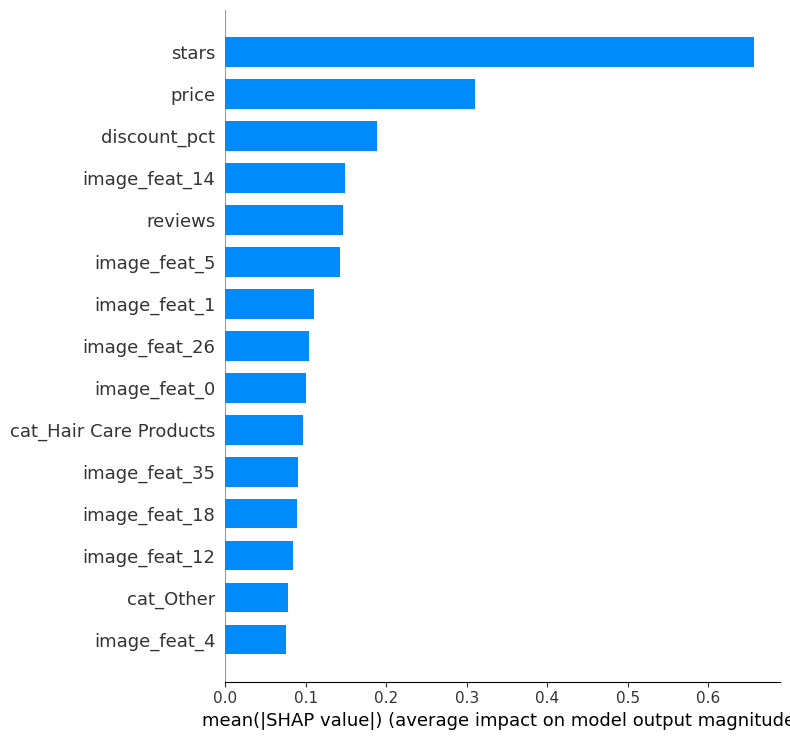

In [40]:
feature_names = (['price', 'stars', 'reviews', 'discount_pct']
                  + list(category_dummies_v3.columns)
                  + [f'title_word_{i}' for i in range(300)]
                  + [f'image_feat_{i}' for i in range(50)])

shap.summary_plot(shap_values, X_test_sample, feature_names=feature_names, max_display=15, plot_type='bar')

In [41]:
from google.colab import userdata
import google.generativeai as genai

api_key = userdata.get('GEMINI_API_KEY')
genai.configure(api_key=api_key)

print("Gemini API bağlantısı kuruldu!")

/usr/local/lib/python3.13/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Gemini API bağlantısı kuruldu!


In [42]:
!pip install google-generativeai -q

In [43]:
test_product = df_valid2.iloc[0]
test_img_url = test_product['imgUrl']

print("Test ürünü:", test_product['title'])

Test ürünü: LOVEVOOK Diaper Bag Backpack, Diaper Backpack with Portable Changing Pad & Pacifier Case,Multipurpose Travel Back Pack for Moms Dads


In [44]:
test_product_for_llm = test_product  # daha önce test ettiğimiz bebek bezi çantası

prompt = f"""
Bir e-ticaret ürün başarı danışmanısın. Aşağıdaki ürün bilgilerine bakarak, satışını artırmak için 3 somut öneri ver.

Ürün başlığı: {test_product_for_llm['title']}
Kategori: {test_product_for_llm['category_grouped']}
Fiyat: {test_product_for_llm['price']} USD
Liste fiyatı: {test_product_for_llm['listPrice']} USD
Yıldız puanı: {test_product_for_llm['stars']}
Yorum sayısı: {test_product_for_llm['reviews']}
Modelin tahmin ettiği başarı olasılığı: %23.9 (düşük)

Lütfen:
1. Başlık için 2 alternatif öner (daha dikkat çekici)
2. Fiyatlandırma hakkında bir öneri
3. Genel bir strateji önerisi

Kısa ve net cevap ver.
"""

model_llm = genai.GenerativeModel('gemini-3.6-flash')
response = model_llm.generate_content(prompt)

print(response.text)

Bir E-ticaret Ürün Başarı Danışmanı olarak, ürününüzün düşük başarı olasılığını (%23.9) hızla yükseltecek **3 somut önerim**:

### 1. Başlık için 2 Alternatif (Daha Dinamik ve SEO Odaklı)
Mevcut başlık "Diaper Bag" kelimesini gereksiz yere tekrarlıyor. Daha net ve arama hacmi yüksek şu alternatifleri kullanabilirsiniz:

*   **Alternatif 1 (SEO ve Fayda Odaklı):** 
    * *LOVEVOOK All-in-One Diaper Bag Backpack with Changing Pad & Pacifier Holder - Stylish Travel Baby Bag for Mom & Dad*
*   **Alternatif 2 (Özellik Odaklı):** 
    * *LOVEVOOK Large Waterproof Diaper Backpack - Multi-Function Travel Baby Bag with Portable Changing Station*

### 2. Fiyatlandırma Önerisi
*   **Çapa Fiyatı (Anchor Pricing) ve Lansman Kuponu Oluşturun:** Liste fiyatınız $0.0 görünüyor. Ürüne **$49.99** Liste Fiyatı girip üzerini çizdirerek **$36.99** satış fiyatını "İndirim" gibi gösterin. Ayrıca 0 yorumlu bir ürünün riskini azaltmak için sepette geçerli **%10-%15 lansman kuponu** tanımlayın.

### 3. Genel St

In [45]:
def get_product_recommendation(product_row, model, explainer, feature_names, tfidf_obj, category_columns, pca_obj):
    # 1) Ürünün özelliklerini hazırla (fotoğraf hariç, basitlik için sadece metin+sayısal)
    title_feat = tfidf_obj.transform([product_row['title']])

    cat_dummies = pd.DataFrame(0, index=[0], columns=category_columns)
    cat_col = 'cat_' + product_row['category_grouped']
    if cat_col in cat_dummies.columns:
        cat_dummies[cat_col] = 1
    else:
        cat_dummies['cat_Other'] = 1

    numeric = np.array([[product_row['price'], product_row['stars'],
                          product_row['reviews'], product_row['discount_pct']]])

    # Görsel özellik olmadan basit bir tahmin (hız için)
    dummy_image = np.zeros((1, 50))

    X_product = hstack([csr_matrix(numeric), csr_matrix(cat_dummies.values),
                         title_feat, csr_matrix(dummy_image)])

    # 2) Tahmin al
    prob = model.predict_proba(X_product)[0][1] * 100

    # 3) SHAP ile en etkili 3 özelliği bul
    shap_vals = explainer.shap_values(X_product)[0]
    top_indices = np.argsort(np.abs(shap_vals))[-3:][::-1]
    top_features = [(feature_names[i], shap_vals[i]) for i in top_indices]

    shap_summary = "\n".join([f"- {name}: {'positive' if val > 0 else 'negative'} impact"
                                for name, val in top_features])

    # 4) Prompt oluştur ve LLM'e gönder
    prompt = f"""
You are an e-commerce product success consultant.

Product title: {product_row['title']}
Category: {product_row['category_grouped']}
Price: {product_row['price']} USD
Star rating: {product_row['stars']}
Predicted success probability: {prob:.1f}%

Top factors influencing this prediction (from model explainability analysis):
{shap_summary}

Based on this, give:
1. 2 alternative titles
2. A pricing suggestion
3. One overall strategy tip

Keep it short and actionable.
"""

    model_llm = genai.GenerativeModel('gemini-3.6-flash')
    response = model_llm.generate_content(prompt)

    return prob, response.text

In [46]:
prob, recommendation = get_product_recommendation(
    test_product, model_with_images_v3, explainer, feature_names,
    tfidf, category_dummies_v3.columns, pca2
)

print(f"Başarı olasılığı: %{prob:.1f}")
print("\nÖneri:\n", recommendation)

Başarı olasılığı: %3.9

Öneri:
 Here are your actionable recommendations to drastically improve conversion and product success:

### 1. Alternative Titles
* **Option 1 (SEO & Clarity Focused):**  
  `LOVEVOOK Diaper Bag Backpack with Changing Pad & Pacifier Case – Waterproof Baby Travel Bag for Moms & Dads`
* **Option 2 (Benefit & Capacity Focused):**  
  `LOVEVOOK Large Capacity Diaper Backpack – Multi-Function Baby Travel Bag with Portable Changing Mat & Pacifier Holder`

---

### 2. Pricing Suggestion
* **Target Price:** **$32.99 – $34.99** (or keep $36.99 with an active **15% on-page coupon**).  
* **Rationale:** The $30–$35 range is a high-conversion sweet spot for mid-tier diaper bags. Adding a coupon tag improves click-through rate (CTR) and visual urgency in search results.

---

### 3. Overall Strategy Tip
* **Fix Categorization & Overhaul Main Image (Hero Shot):**  
  1. **Category Fix:** Move the product out of the generic **"Other"** category into **"Baby Products > Diaper 

In [47]:
!pip install gradio -q

In [48]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np

def fill_example():
    return "Wireless Bluetooth Headphones with Noise Cancellation", list(category_dummies_v3.columns.str.replace('cat_', ''))[0], 29.99, 49.99, 4.3, 85

def predict_and_recommend(title, category, price, list_price, stars, reviews):
    discount_pct = (list_price - price) / list_price if list_price > 0 else 0
    product_data = pd.Series({'title': title, 'category_grouped': category, 'price': price, 'listPrice': list_price, 'stars': stars, 'reviews': reviews, 'discount_pct': discount_pct})

    title_feat = tfidf.transform([product_data['title']])
    cat_dummies = pd.DataFrame(0, index=[0], columns=category_dummies_v3.columns)
    cat_col = 'cat_' + product_data['category_grouped']
    if cat_col in cat_dummies.columns:
        cat_dummies[cat_col] = 1
    else:
        cat_dummies['cat_Other'] = 1
    numeric = np.array([[product_data['price'], product_data['stars'], product_data['reviews'], product_data['discount_pct']]])
    dummy_image = np.zeros((1, 50))
    X_product = hstack([csr_matrix(numeric), csr_matrix(cat_dummies.values), title_feat, csr_matrix(dummy_image)])

    prob = model_with_images_v3.predict_proba(X_product)[0][1] * 100
    shap_vals = explainer.shap_values(X_product)[0]
    top_indices = np.argsort(np.abs(shap_vals))[-5:]
    top_names = [feature_names[i] for i in top_indices]
    top_values = [shap_vals[i] for i in top_indices]

    fig, ax = plt.subplots(figsize=(6, 4))
    cmap = plt.cm.RdYlGn
    normalized = (np.array(top_values) - min(top_values)) / (max(top_values) - min(top_values) + 1e-9)
    colors = [cmap(n) for n in normalized]
    ax.barh(top_names, top_values, color=colors)
    ax.set_xlabel("Etki Gucu")
    ax.set_title("En Etkili 5 Ozellik")
    plt.tight_layout()

    shap_summary = "\n".join(["- " + str(top_names[i]) + ": " + ("positive" if top_values[i] > 0 else "negative") for i in range(len(top_names))])

    prompt = "You are an e-commerce product success consultant.\n\nProduct title: " + str(product_data['title']) + "\nCategory: " + str(product_data['category_grouped']) + "\nPrice: " + str(product_data['price']) + " USD\nStar rating: " + str(product_data['stars']) + "\nPredicted success probability: " + str(round(prob,1)) + "%\n\nTop factors:\n" + shap_summary + "\n\nGive: 1) 2 alternative titles 2) A pricing suggestion 3) One strategy tip. Keep it short."

    model_llm = genai.GenerativeModel('gemini-3.6-flash')
    response = model_llm.generate_content(prompt)

    if prob >= 60:
        card_color = "#D4F4E4"
        card_text_color = "#1A6B4A"
        emoji = "😄"
        status = "Harika gorunuyor!"
    elif prob >= 30:
        card_color = "#FFF4D6"
        card_text_color = "#8A6D00"
        emoji = "😐"
        status = "Orta seviyede."
    else:
        card_color = "#FADBD8"
        card_text_color = "#943126"
        emoji = "😢"
        status = "Gelisim alani var."

    prob_html = "<div style='background-color:" + card_color + "; padding:20px; border-radius:12px; text-align:center;'><h2 style='color:" + card_text_color + "; margin:0;'>" + emoji + " Basari Olasiligi: %" + str(round(prob, 1)) + "</h2><p style='color:" + card_text_color + "; margin:5px 0 0 0;'>" + status + "</p></div>"

    return prob_html, fig, response.text

custom_css = """
.gradio-container {
    background-color: #171923;
    background-image:
        radial-gradient(circle at top left, rgba(129, 140, 248, 0.10) 0%, transparent 35%),
        radial-gradient(circle at bottom right, rgba(45, 212, 191, 0.10) 0%, transparent 35%);
}
input, textarea, select {background-color: #232634 !important; color: #F5F5F5 !important;}
"""

with gr.Blocks(theme=gr.themes.Soft(primary_hue="teal", secondary_hue="violet"), css=custom_css) as demo:
    gr.Markdown("# AI Product Success Predictor")
    gr.Markdown("Urununuzun bilgilerini girin, yapay zeka basari olasiligini tahmin etsin ve size ozel oneriler sunsun.")
    with gr.Row():
        with gr.Column():
            gr.Markdown("### Urun Bilgileri")
            example_btn = gr.Button("Ornek Doldur", variant="secondary")
            title_input = gr.Textbox(label="Urun Basligi")
            category_input = gr.Dropdown(label="Kategori", choices=list(category_dummies_v3.columns.str.replace('cat_', '')))
            price_input = gr.Number(label="Fiyat (USD)", value=29.99)
            list_price_input = gr.Number(label="Liste Fiyati (USD)", value=39.99)
            stars_input = gr.Slider(label="Yildiz Puani", minimum=1, maximum=5, value=4.5, step=0.1)
            reviews_input = gr.Number(label="Yorum Sayisi", value=50)
            submit_btn = gr.Button("Tahmin Et ve Oner", variant="primary")
        with gr.Column():
            gr.Markdown("### Sonuc")
            prob_output = gr.HTML()
            plot_output = gr.Plot(label="Etki Analizi")
            gr.Markdown("### Oneriler")
            recommendation_output = gr.Textbox(label="", lines=8)

    example_btn.click(fn=fill_example, inputs=[], outputs=[title_input, category_input, price_input, list_price_input, stars_input, reviews_input])
    submit_btn.click(fn=predict_and_recommend, inputs=[title_input, category_input, price_input, list_price_input, stars_input, reviews_input], outputs=[prob_output, plot_output, recommendation_output])

demo.launch(debug=True)

/tmp/ipykernel_4182/3653561412.py:75: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue="teal", secondary_hue="violet"), css=custom_css) as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://33c1db51b933e74dd8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://33c1db51b933e74dd8.gradio.live


In [49]:
def load_and_prepare_dataset(csv_path, column_mapping, success_column, success_threshold):
    df_new = pd.read_csv(csv_path)
    df_new = df_new.rename(columns={v: k for k, v in column_mapping.items()})
    df_new['success'] = (df_new[success_column] > success_threshold).astype(int)
    print("Veri seti yuklendi:", df_new.shape)
    print("Basari orani:", df_new['success'].mean())
    return df_new

In [50]:
def train_pipeline_on_new_dataset(df_new, min_category_count=None):
    if min_category_count is None:
        min_category_count = len(df_new) // 15

    category_counts = df_new['category'].value_counts()
    top_categories = category_counts[category_counts >= min_category_count].index
    df_new['category_grouped'] = df_new['category'].where(df_new['category'].isin(top_categories), 'Other')

    new_tfidf = TfidfVectorizer(max_features=300, stop_words='english')
    new_title_features = new_tfidf.fit_transform(df_new['title'].fillna(''))

    new_category_dummies = pd.get_dummies(df_new['category_grouped'], prefix='cat')

    df_new['discount_pct'] = (df_new['list_price'] - df_new['price']) / df_new['list_price']
    df_new['discount_pct'] = df_new['discount_pct'].replace([np.inf, -np.inf], 0).fillna(0)

    new_numeric = df_new[['price', 'stars', 'reviews', 'discount_pct']].fillna(0).values

    new_X = hstack([csr_matrix(new_numeric), csr_matrix(new_category_dummies.values), new_title_features])
    new_y = df_new['success']

    X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(new_X, new_y, test_size=0.2, random_state=42, stratify=new_y)

    scale_weight = (y_train_new == 0).sum() / (y_train_new == 1).sum()

    new_model = XGBClassifier(n_estimators=200, max_depth=6, random_state=42, eval_metric='logloss', scale_pos_weight=scale_weight)
    new_model.fit(X_train_new, y_train_new)

    y_pred_new = new_model.predict(X_test_new)
    print("Accuracy:", accuracy_score(y_test_new, y_pred_new))
    print(classification_report(y_test_new, y_pred_new))

    return new_model, new_tfidf, new_category_dummies.columns, df_new